# NESS with analytic photons and grid phonons on the IBZ + s window
Photons: `cv.CavityBath` (q integrated analytically, vertical). Phonons: `PhononBath(kind="phonon")` on the full grid.
Both amplitudes are multiplied by a common `lam`, which does not change the NESS, only the absolute rate scale seen by `tol`.

In [54]:
import sys
from pathlib import Path
from dataclasses import replace
import numpy as np
import yaml
import jax.numpy as jnp
import matplotlib.pyplot as plt
import colormaps as cmaps
from tqdm.notebook import tqdm

ROOT = Path("/home/kzeleznikar/IJS-F1/Koda")
CFG = ROOT / "EI_cutoff" / "config" / "config_ibz.yaml"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import EI.ei_unified as eu
import EI.ei_jax_2 as ej
import EI.ei_phonon as pb
import EI.ei_cavity as cv
import EI.ei_ibz as ibz
from utils.cosmetics import apply_plt_style, SET1_LIST
from utils.logger import logger
from utils.plotting_utils import Plotter, plot_cmap

apply_plt_style()
pt = Plotter(show=True, close=False)
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)
FIG_PATH = "/home/kzeleznikar/IJS-F1/Notes/latex/figures/"

## Parameters

In [55]:
with CFG.open("r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
md_, eq, op = cfg["model"], cfg["equilibrium"], cfg["open_system"]
bp = md_["band"]["pars"]
p = eu.MFPars(**md_["mean_field"])
bc = op["bath"]
bq = dict(bc["pars"])          # shared bath pars (band, mean field, nsub)
og, oph = bc["baths"]          # (photon, phonon) dicts from the yaml

nk = md_["nk"].get("ibz", md_["nk"]["scan"])   # even, high is fine with a small window
t1n, t2n = 0.8, 0.2            # single NESS point: T1 / Tc (photons), T2 / Tc (phonons)
t1r = np.linspace(0.05, 2.5, 10)   # phase diagram, T1 / Tc
t2r = np.linspace(0.05, 1.5, 10)   # phase diagram, T2 / Tc
ncut = 3.0                    # window keeps E - E_min <= ncut * max(T)
lam = 1.0 / oph["amp"]         # common rate scale, NESS independent of it
kw = dict(mix=(0.5, 0.5, 0.1), tol=1.0e-4, nmax=20000, chk=50, prog=False, jtol=1.0e-2, pc=True)

## Bands, equilibrium and $T_c$ on the IBZ

In [56]:
bi, ib = ibz.tb_2d_ibz(nk, **bp)
s0 = eu.solve_eq(bi, p, **eq["initial"], **eq["solve"])
d0, m0 = max(abs(float(s0.d)), 1.0e-12), float(s0.m)
tc = float(eu.critical_temperature(bi, p, **eq["critical"]))
logger.info(f"nk = {nk}, N_I = {ib.mult.size}, Delta_0 = {d0:.5f}, m0 = {m0:.5f}, Tc = {tc:.5f}")

kriticna temp bisekcija:   0%|          | 0/80 [00:00<?, ?it/s]

[17:49:54] [INFO    ] nk = 150, N_I = 2926, Delta_0 = 0.14497, m0 = -0.86083, Tc = 0.08174


## Baths
`mk(T1, T2)` returns (phonon on the full grid `ib.kf`, analytic photon). The yaml photon entry gives `amp`, `cs` (used as `c`), `w0`, `gam`.
`nsub = 0`: no cell averaged line table, the phonon line is sampled at the grid q (resolution `cs * 2 pi / nk` must be well below `gam`).

In [57]:
def mk(T1, T2):
    ph = fn(T2, ib.kf, name="phonon", **{**bq, **oph, "nsub": 0, "amp": lam * oph["amp"]})
    cb = cv.CavityBath(t=T1, w0=og["w0"], gam=og["gam"], ta=bp["ta"], tb=bp["tb"],
                       c=og["cs"], amp=lam * og["amp"])
    return ph, cb

fn = getattr(pb, bc["rate"])
logger.info(f"phonon line resolution cs * dk = {oph['cs'] * 2 * np.pi / nk:.1e} vs gam = {oph['gam']}")

[17:49:54] [INFO    ] phonon line resolution cs * dk = 1.1e-03 vs gam = 0.05


## s window
Kept: states with $E - E_{\min} \le$ `ncut` $\cdot T_{\max}$, evaluated at the equilibrium gap. Since $E$ depends on $s$ through $|\xi|$ only, this is one interval in $s$. Outside, $n_\alpha = 0$ and $n_\beta = 1$ are frozen; photon pumping there is $\propto N(2E) \le e^{-2\,\mathrm{ncut}}$.

In [58]:
def s_window(tmax, d=d0, m=m0):
    st = ej.mf_state(bi, p, d, m)
    E = 0.5 * np.asarray(st.e[0] - st.e[1])
    s = np.cos(ib.ki[:, 0]) + np.cos(ib.ki[:, 1])
    keep = E - E.min() <= ncut * tmax
    pad = 2.0 * np.sqrt(2.0) * 2 * np.pi / nk   # two grid steps in s, abs(grad s) <= sqrt 2
    return max(s[keep].min() - pad, -2.0), min(s[keep].max() + pad, 2.0)

def mem(sw):
    wi, _ = ibz.win_index(ib, *sw)
    gb = 30 * (2 * wi.size) * (2 * nk * nk) * 8e-9   # about 30 pair temporaries
    return wi.size, wi.size / ib.mult.size, gb

sw1 = s_window(max(t1n, t2n) * tc)
swd = s_window(max(t1r.max(), t2r.max()) * tc)
for q, z in (("single point", sw1), ("phase diagram", swd)):
    n_w, f_w, gb = mem(z)
    logger.info(f"{q}: s in [{z[0]:.3f}, {z[1]:.3f}], N_W = {n_w}, f = {f_w:.3f}, rate build ~ {gb:.1f} GB")

[17:49:54] [INFO    ] single point: s in [1.319, 1.861], N_W = 286, f = 0.098, rate build ~ 6.2 GB
[17:49:54] [INFO    ] phase diagram: s in [1.102, 2.000], N_W = 489, f = 0.167, rate build ~ 10.6 GB


## Single NESS point

In [59]:
ph, cb = mk(t1n * tc, t2n * tc)
wb = ibz.WinBaths((ph, cb), ib, *sw1)
se = eu.solve_eq(bi, p, t=t2n * tc, d=d0, m=m0, **{**eq["solve"], "prog": False})
so = ej.solve_fixed(bi, p, ibz.freeze(se.n, bi, p, wb), wb, d=float(se.d), m=float(se.m),
                    **{**kw, "prog": True})
logger.info(f"d/d0 = {so.d / d0:.5f}, m = {so.m:.5f}, err = {so.err:.1e}, ok = {so.ok}, it = {so.it}")

Fixed EI JAX:   0%|          | 0/400 [00:00<?, ?it/s]

[17:49:57] [INFO    ] d/d0 = 0.73694, m = -0.86186, err = 7.5e-05, ok = True, it = 900


## Occupations in the BZ with the window
Left: $n_{\alpha\mathbf k}$, right: $h_{\beta\mathbf k} = 1 - n_{\beta\mathbf k}$. Dashed: window edges $s_{\min}, s_{\max}$. `zoom` limits the axes to the window.

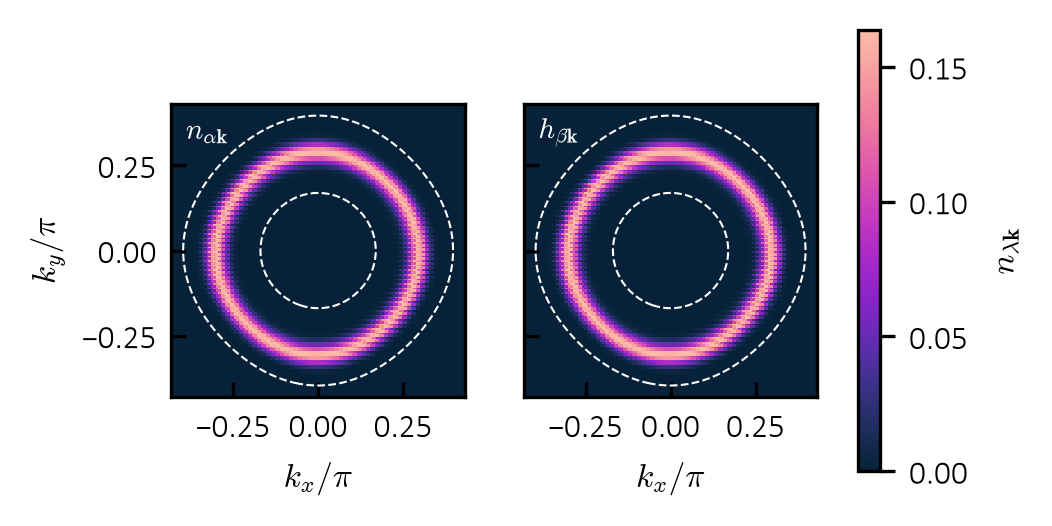

In [60]:
zoom, logc = True, False
q = np.linspace(-np.pi, np.pi, nk, endpoint=False) / np.pi
na = ibz.unfold(so.n[0], ib)
hb = 1.0 - ibz.unfold(so.n[1], ib)
sg = np.cos(np.pi * q)[:, None] + np.cos(np.pi * q)[None, :]
vm = max(na.max(), hb.max())
lim = 1.1 * np.hypot(q[:, None], q[None, :])[(sg >= sw1[0]) & (sg <= sw1[1])].max() if zoom else 1.0
nrm = plt.matplotlib.colors.LogNorm(vmin=1e-8 * vm, vmax=vm) if logc else plt.Normalize(0.0, vm)

fig, axs = plt.subplots(1, 2, figsize=(3.47412, 0.55 * 3.47412), sharey=True)
for ax, z, lb in zip(axs, (na, hb), (r"$n_{\alpha\mathbf{k}}$", r"$h_{\beta\mathbf{k}}$")):
    im = ax.pcolormesh(q, q, np.maximum(z, 1e-300).T, cmap=cmaps.bubblegum, norm=nrm, shading="nearest")
    im.set_edgecolor("face")
    ax.contour(q, q, sg.T, levels=sorted(set(sw1)), colors="w", linewidths=0.5, linestyles="--")
    ax.text(0.05, 0.88, lb, transform=ax.transAxes, color="w", fontsize=7)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xlabel(r"$k_x/\pi$"); ax.tick_params(which="both", direction="in")
axs[0].set_ylabel(r"$k_y/\pi$")
cbar = fig.colorbar(im, ax=axs.tolist())
cbar.set_label(r"$n_{\lambda\mathbf{k}}$", rotation=90, labelpad=5)
# fig.savefig(FIG_PATH + "ness_bz_window.pdf", bbox_inches="tight")

## Bands along $\Gamma$–X–M–$\Gamma$
Bare $\varepsilon_{a,b}$, Hartree shifted $\varepsilon^H_{a,b}$ (same energy frame as `ej._mf`, shift $-U_H/2$), quasiparticle $E_{\alpha,\beta}$ of the NESS. Right: bath dispersions $\omega_{\mathbf q}$ with $\mathbf q$ along the same path (photon only near $\Gamma$, $\tilde c = 3945$).

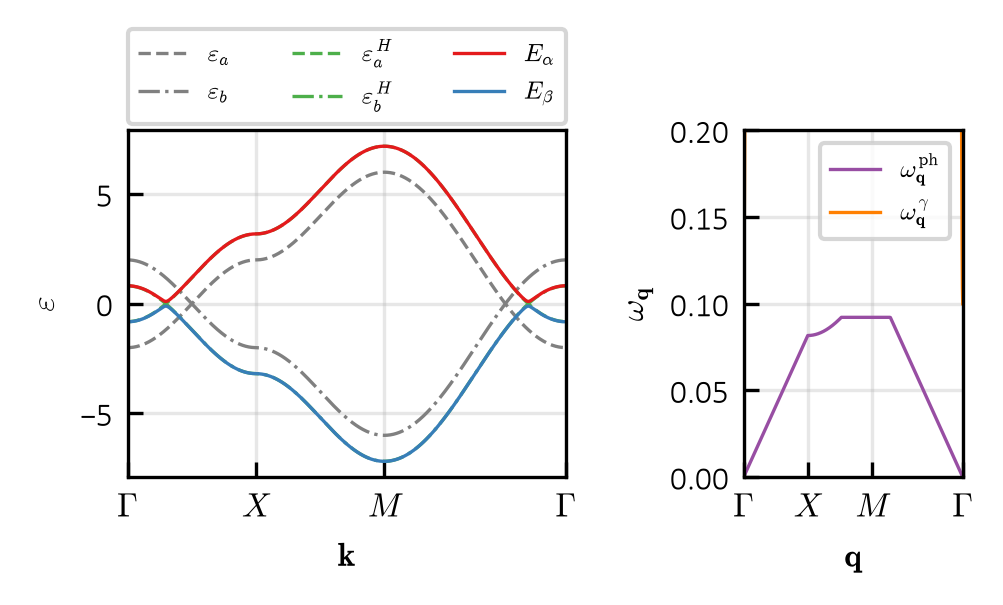

In [61]:
def kpath(n=300):
    G, X, M = np.array([0.0, 0.0]), np.array([np.pi, 0.0]), np.array([np.pi, np.pi])
    seg = [(G, X), (X, M), (M, G)]
    ks = np.concatenate([a + (b - a) * np.linspace(0, 1, n, endpoint=False)[:, None] for a, b in seg] + [G[None]])
    x = np.concatenate(([0.0], np.cumsum(np.linalg.norm(np.diff(ks, axis=0), axis=1))))
    return ks, x, x[[0, n, 2 * n, 3 * n]]

ks, x, xt = kpath()
s = np.cos(ks[:, 0]) + np.cos(ks[:, 1])
st = ej.mf_state(bi, p, so.d, so.m)
na_, nb_, h = float(st.na), float(st.nb), p.h
ea, eb = 0.5 * bp["gap"] - 2 * bp["ta"] * s, -0.5 * bp["gap"] - 2 * bp["tb"] * s
eah, ebh = ea + h * nb_ - 0.5 * h, eb + h * na_ - 0.5 * h
xi, av = 0.5 * (eah - ebh), 0.5 * (eah + ebh)
Ea, Eb = av + np.hypot(xi, so.d), av - np.hypot(xi, so.d)
qn = np.linalg.norm(ks, axis=1)

fig, (ax, bx) = plt.subplots(1, 2, figsize=(3.47412, 0.6 * 3.47412), gridspec_kw={"width_ratios": [2, 1]})
for z, c, ls, lb in ((ea, "grey", "--", r"$\varepsilon_a$"), (eb, "grey", "-.", r"$\varepsilon_b$"),
                     (eah, SET1_LIST[2], "--", r"$\varepsilon^H_a$"), (ebh, SET1_LIST[2], "-.", r"$\varepsilon^H_b$"),
                     (Ea, SET1_LIST[0], "-", r"$E_\alpha$"), (Eb, SET1_LIST[1], "-", r"$E_\beta$")):
    ax.plot(x, z, color=c, ls=ls, lw=0.8, label=lb)
ax.set_xlim(x[0], x[-1]); ax.set_xticks(xt, [r"$\Gamma$", r"$X$", r"$M$", r"$\Gamma$"])
ax.set_xlabel(r"$\mathbf{k}$"); ax.set_ylabel(r"$\varepsilon$")
ax.grid(alpha=0.3); ax.tick_params(which="both", direction="in")
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", borderaxespad=0, ncol=3, fontsize=6)

wph = oph["cs"] * np.minimum(qn, ph.qd)
wga = np.hypot(og["w0"], og["cs"] * qn)
bx.plot(x, wph, color=SET1_LIST[3], lw=0.8, label=r"$\omega^{\mathrm{ph}}_{\mathbf{q}}$")
bx.plot(x, wga, color=SET1_LIST[4], lw=0.8, label=r"$\omega^{\gamma}_{\mathbf{q}}$")
bx.set_xlim(x[0], x[-1]); bx.set_ylim(0.0, 2.0 * max(wph.max(), og["w0"]))
bx.set_xticks(xt, [r"$\Gamma$", r"$X$", r"$M$", r"$\Gamma$"])
bx.set_xlabel(r"$\mathbf{q}$"); bx.set_ylabel(r"$\omega_{\mathbf{q}}$")
bx.grid(alpha=0.3); bx.tick_params(which="both", direction="in"); bx.legend(fontsize=6)
plt.tight_layout()
# fig.savefig(FIG_PATH + "bands_ness.pdf", bbox_inches="tight")

## Phase diagram
Fixed window `swd` from the largest temperature of the sweep (a changing window would recompile every point). Warm starts along $T_1$, each row starts from the previous row's first point, gap floor `ds` with a warm up retry.

In [62]:
tbk = tc * np.array([0.5, 1.0, 1.5, 2.5])       # window buckets in max(T1, T2)
wins = {t: s_window(t) for t in tbk}

def win(T1, T2):
    return wins[tbk[np.searchsorted(tbk, max(T1, T2) * (1 - 1e-12))]]

In [63]:
ds, nw = 1.0e-3, 200

def sweep():
    dm = np.full((t2r.size, t1r.size), np.nan)
    mm, ok = np.full_like(dm, np.nan), np.zeros(dm.shape, dtype=bool)
    wb = ibz.WinBaths(mk(tc, tc), ib, *swd)
    s0 = (ibz.freeze(s0e.n, bi, p, wb), float(s0e.d), float(s0e.m))
    for i in tqdm(range(t2r.size), desc="T2 sweep"):
        sv = s0
        for j in tqdm(range(t1r.size), leave=False):
            wb = ibz.WinBaths(mk(t1r[j] * tc, t2r[i] * tc), ib, *win(t1r[j] * tc, t2r[i] * tc))
            n0, dv, mv = sv
            n0 = ibz.freeze(n0, bi, p, wb)   # warm start may come from another window
            sn = ej.solve_fixed(bi, p, n0.copy(), wb, d=max(abs(dv), ds), m=mv, **kw)
            if abs(float(sn.d)) < ds:  # retry from a warm up
                w0_ = ej.solve_fixed(bi, p, sn.n.copy(), wb, d=ds, m=float(sn.m), **{**kw, "nmax": nw})
                sn = ej.solve_fixed(bi, p, w0_.n.copy(), wb, d=float(w0_.d), m=float(w0_.m), **kw)
            dm[i, j], mm[i, j], ok[i, j] = sn.d, sn.m, bool(sn.ok)
            if np.isfinite(sn.err):
                sv = (sn.n, float(sn.d), float(sn.m))
                if j == 0:
                    s0 = sv
    return dm, mm, ok

s0e = eu.solve_eq(bi, p, t=t2r[0] * tc, d=d0, m=m0, **{**eq["solve"], "prog": False})
dm, mm, okm = sweep()
logger.info(f"unconverged: {(~okm).sum()} of {okm.size}")
# np.savez("phase_ibz_cav.npz", t1r=t1r, t2r=t2r, d=dm, m=mm, ok=okm, d0=d0, tc=tc, sw=np.array(swd))

T2 sweep:   0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
fd_, _ = plot_cmap(t1r, t2r, dm / d0, r"$\Delta/\Delta_0$", pt=pt)
fm_, _ = plot_cmap(t1r, t2r, mm, r"$m$", pt=pt, cmap=cmaps.lapaz.cut(0.1, "right"))
# fd_.savefig(FIG_PATH + "gap_map_ibz_cav.pdf", bbox_inches="tight")
# fm_.savefig(FIG_PATH + "m_map_ibz_cav.pdf", bbox_inches="tight")

In [ ]:
import time
for T1, T2 in ((0.05, 0.05), (0.8, 0.2), (2.5, 0.05), (0.05, 1.5)):
    wb = ibz.WinBaths(mk(T1 * tc, T2 * tc), ib, *swd)
    t0 = time.perf_counter()
    sn = ej.solve_fixed(bi, p, ibz.freeze(s0e.n, bi, p, wb), wb, d=d0, m=m0, **kw)
    logger.info(f"T1={T1}, T2={T2}: {time.perf_counter() - t0:.1f} s, it = {sn.it}, "
                f"ok = {sn.ok}, err = {sn.err:.1e}, d/d0 = {sn.d / d0:.3f}")

[17:37:50] [INFO    ] T1=0.05, T2=0.05: 131.7 s, it = 20000, ok = False, err = 1.1e-02, d/d0 = 0.952
[17:37:52] [INFO    ] T1=0.8, T2=0.2: 1.6 s, it = 200, ok = True, err = 7.7e-10, d/d0 = 1.000
[17:40:02] [INFO    ] T1=2.5, T2=0.05: 130.9 s, it = 20000, ok = False, err = 2.0e-02, d/d0 = 0.915
[17:42:15] [INFO    ] T1=0.05, T2=1.5: 132.1 s, it = 20000, ok = False, err = 2.0e-04, d/d0 = 0.000
